# View sample xBD images and labels
This notebook shows pre/post disaster image pairs (GeoTIFF, read with rasterio) and the label JSON files that go with them.

In [1]:
import json
import random
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import rasterio

## 1. Find the image pairs

In [4]:
# Change "tier1" to "test" or "hold" to look at other splits.
# The path is relative to the folder where the notebook is saved (final_project).
IMAGES_DIR = Path("../geotiffs/tier1/images")

pre_files = sorted(IMAGES_DIR.glob("*_pre_disaster.tif"))

pairs = []
for pre in pre_files:
    post = pre.with_name(pre.name.replace("_pre_disaster", "_post_disaster"))
    if post.exists():
        pairs.append((pre, post))

print("Pre-disaster files:", len(pre_files))
print("Pairs found:", len(pairs))

# Number of pairs per disaster (the disaster name is the first part of the file name)
print(Counter(pre.name.split("_")[0] for pre, _ in pairs))

Pre-disaster files: 2799
Pairs found: 2799
Counter({'socal-fire': 823, 'hurricane-michael': 343, 'hurricane-florence': 319, 'hurricane-harvey': 319, 'midwest-flooding': 279, 'hurricane-matthew': 238, 'santa-rosa-wildfire': 226, 'mexico-earthquake': 121, 'palu-tsunami': 113, 'guatemala-volcano': 18})


In [ ]:
# Change "tier1" to "test" or "hold" to look at other splits.
# The path is relative to the folder where the notebook is saved (final_project).
IMAGES_DIR = Path("../geotiffs/tier3/images")

pre_files = sorted(IMAGES_DIR.glob("*_pre_disaster.tif"))

pairs = []
for pre in pre_files:
    post = pre.with_name(pre.name.replace("_pre_disaster", "_post_disaster"))
    if post.exists():
        pairs.append((pre, post))

print("Pre-disaster files:", len(pre_files))
print("Pairs found:", len(pairs))

# Number of pairs per disaster (the disaster name is the first part of the file name)
print(Counter(pre.name.split("_")[0] for pre, _ in pairs))

Pre-disaster files: 6369
Pairs found: 6369
Counter({'portugal-wildfire': 1869, 'pinery-bushfire': 1845, 'woolsey-fire': 878, 'nepal-flooding': 619, 'tuscaloosa-tornado': 343, 'lower-puna-volcano': 291, 'moore-tornado': 227, 'joplin-tornado': 149, 'sunda-tsunami': 148})


In [ ]:
# Change "tier1" to "test" or "hold" to look at other splits.
# The path is relative to the folder where the notebook is saved (final_project).
IMAGES_DIR = Path("../geotiffs/test/images")

pre_files = sorted(IMAGES_DIR.glob("*_pre_disaster.tif"))

pairs = []
for pre in pre_files:
    post = pre.with_name(pre.name.replace("_pre_disaster", "_post_disaster"))
    if post.exists():
        pairs.append((pre, post))

print("Pre-disaster files:", len(pre_files))
print("Pairs found:", len(pairs))

# Number of pairs per disaster (the disaster name is the first part of the file name)
print(Counter(pre.name.split("_")[0] for pre, _ in pairs))

Pre-disaster files: 933
Pairs found: 933
Counter({'socal-fire': 307, 'hurricane-florence': 108, 'hurricane-harvey': 108, 'hurricane-michael': 98, 'midwest-flooding': 80, 'santa-rosa-wildfire': 74, 'hurricane-matthew': 73, 'palu-tsunami': 42, 'mexico-earthquake': 38, 'guatemala-volcano': 5})


In [12]:
# Change "tier1" to "test" or "hold" to look at other splits.
# The path is relative to the folder where the notebook is saved (final_project).
IMAGES_DIR = Path("geotiffs/hold/images")

pre_files = sorted(IMAGES_DIR.glob("*_pre_disaster.tif"))

pairs = []
for pre in pre_files:
    post = pre.with_name(pre.name.replace("_pre_disaster", "_post_disaster"))
    if post.exists():
        pairs.append((pre, post))

print("Pre-disaster files:", len(pre_files))
print("Pairs found:", len(pairs))

# Number of pairs per disaster (the disaster name is the first part of the file name)
print(Counter(pre.name.split("_")[0] for pre, _ in pairs))

Pre-disaster files: 933
Pairs found: 933
Counter({'socal-fire': 273, 'hurricane-florence': 119, 'hurricane-michael': 109, 'hurricane-harvey': 95, 'hurricane-matthew': 94, 'midwest-flooding': 86, 'santa-rosa-wildfire': 77, 'palu-tsunami': 41, 'mexico-earthquake': 34, 'guatemala-volcano': 5})


## 2. Check one image

In [3]:
with rasterio.open(pairs[0][0]) as src:
    print("Bands:", src.count)
    print("Size (width, height):", src.width, src.height)
    print("Data types:", src.dtypes)
    print("CRS:", src.crs)

Bands: 3
Size (width, height): 1024 1024
Data types: ('int16', 'int16', 'int16')
CRS: EPSG:4326


## 3. Show image pairs (left = pre, right = post)

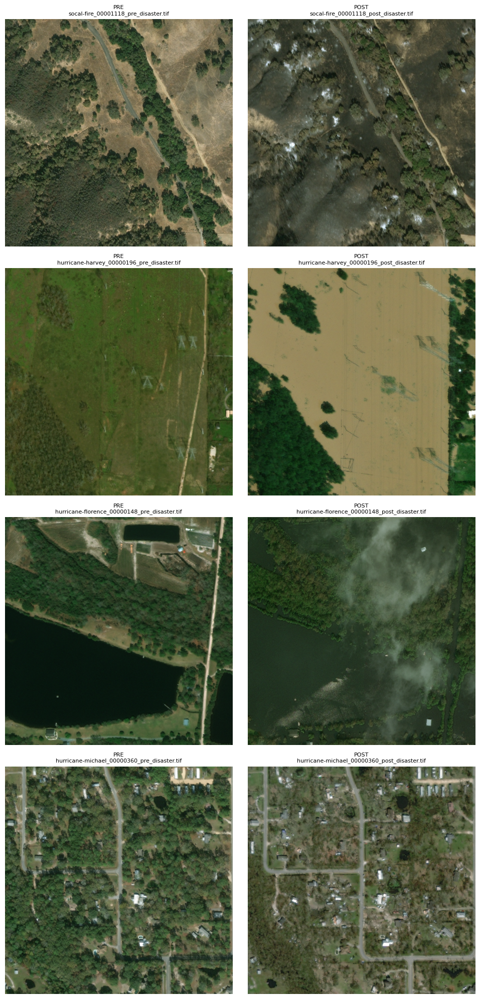

In [4]:
def load_rgb(path):
    """Read a GeoTIFF and return an (H, W, 3) array for display."""
    with rasterio.open(path) as src:
        arr = src.read([1, 2, 3])          # shape: (3, H, W)
    arr = np.transpose(arr, (1, 2, 0))     # shape: (H, W, 3)
    if arr.dtype != np.uint8:              # scale to 0-255 only if not already 8-bit
        arr = arr.astype(np.float32)
        arr = (255 * (arr - arr.min()) / (arr.max() - arr.min() + 1e-8)).astype(np.uint8)
    return arr


def show_pairs(pairs, n=4, seed=42):
    """Show n random pre/post pairs. Left = pre, right = post."""
    random.seed(seed)
    sample = random.sample(pairs, min(n, len(pairs)))

    fig, axes = plt.subplots(len(sample), 2, figsize=(10, 5 * len(sample)))
    axes = np.atleast_2d(axes)

    for row, (pre, post) in zip(axes, sample):
        row[0].imshow(load_rgb(pre))
        row[0].set_title("PRE\n" + pre.name, fontsize=8)
        row[1].imshow(load_rgb(post))
        row[1].set_title("POST\n" + post.name, fontsize=8)
        for ax in row:
            ax.axis("off")

    plt.tight_layout()
    plt.show()


show_pairs(pairs, n=4)

## 4. Look at one label JSON file
Each image has one JSON file with the same name in the `labels` folder.

From the sample JSON, the file has two parts:
- `features`: the list of buildings. Each building has `properties` (`feature_type`, `subtype`, `uid`) and a polygon in `wkt`.
  The polygons are given twice: `lng_lat` (longitude/latitude) and `xy` (pixel positions in the image).
- `metadata`: information about the image (sensor, capture date, disaster name, image size, and so on).

`subtype` is the damage label. It is in the post-disaster file.

In [5]:
def label_path(img_path):
    """images/xxx.tif -> labels/xxx.json (same split folder)."""
    return img_path.parent.parent / "labels" / (img_path.stem + ".json")


def load_label(img_path):
    with open(label_path(img_path)) as f:
        return json.load(f)


lab = load_label(pairs[0][1])  # post-disaster label of the first pair

print("Top-level keys:", list(lab.keys()))
print("Keys in 'features':", list(lab["features"].keys()))
print("Number of buildings:", len(lab["features"]["xy"]))

print("\nFirst building (xy):")
print(json.dumps(lab["features"]["xy"][0], indent=2))

print("\nMetadata:")
for k, v in lab["metadata"].items():
    print(f"  {k}: {v}")

Top-level keys: ['features', 'metadata']
Keys in 'features': ['lng_lat', 'xy']
Number of buildings: 10

First building (xy):
{
  "properties": {
    "feature_type": "building",
    "subtype": "no-damage",
    "uid": "486b0813-ecd2-4b84-856c-9c0e42156953"
  },
  "wkt": "POLYGON ((532.1863714054954 165.9824503000504, 548.6019827848852 224.1613082732768, 446.2458177229872 264.4761185678668, 440.6934785817455 249.7503495372735, 425.9677095499687 253.1300342329752, 420.8981825090282 232.3691139606, 437.5551999358392 227.0581808684396, 431.2786426428399 201.2277335525121, 532.1863714054954 165.9824503000504))"
}

Metadata:
  sensor: WORLDVIEW03_VNIR
  provider_asset_type: WORLDVIEW03_VNIR
  gsd: 1.4085245
  capture_date: 2018-06-22T16:55:40.000Z
  off_nadir_angle: 21.97336
  pan_resolution: 0.35173947
  sun_azimuth: 58.571484
  sun_elevation: 71.182274
  target_azimuth: 314.29373
  disaster: guatemala-volcano
  disaster_type: volcano
  catalog_id: 104001003E575F00
  original_width: 1024
  or

## 5. Compare the pre and post label of the same pair
Check which fields are the same and which are different.

In [6]:
pre_lab = load_label(pairs[0][0])
post_lab = load_label(pairs[0][1])

print("Buildings in pre label: ", len(pre_lab["features"]["xy"]))
print("Buildings in post label:", len(post_lab["features"]["xy"]))
print("Subtypes in pre label: ", Counter(b["properties"].get("subtype", "(no subtype)") for b in pre_lab["features"]["xy"]))
print("Subtypes in post label:", Counter(b["properties"].get("subtype", "(no subtype)") for b in post_lab["features"]["xy"]))

fields = ["sensor", "capture_date", "gsd", "off_nadir_angle", "sun_azimuth", "sun_elevation", "disaster", "disaster_type", "width", "height"]
print(f"\n{'field':18} {'pre':32} {'post'}")
for k in fields:
    print(f"{k:18} {str(pre_lab['metadata'].get(k)):32} {post_lab['metadata'].get(k)}")

Buildings in pre label:  10
Buildings in post label: 10
Subtypes in pre label:  Counter({'(no subtype)': 10})
Subtypes in post label: Counter({'no-damage': 10})

field              pre                              post
sensor             WORLDVIEW03_VNIR                 WORLDVIEW03_VNIR
capture_date       2018-02-05T17:10:18.000Z         2018-06-22T16:55:40.000Z
gsd                1.3459189                        1.4085245
off_nadir_angle    17.933279                        21.97336
sun_azimuth        150.80763000000002               58.571484
sun_elevation      55.506645                        71.182274
disaster           guatemala-volcano                guatemala-volcano
disaster_type      volcano                          volcano
width              1024                             1024
height             1024                             1024


## 6. Draw the building outlines on the images
Colors follow the `subtype` (damage label). Any subtype not in the color table below is drawn in cyan, and the legend lists what was found.

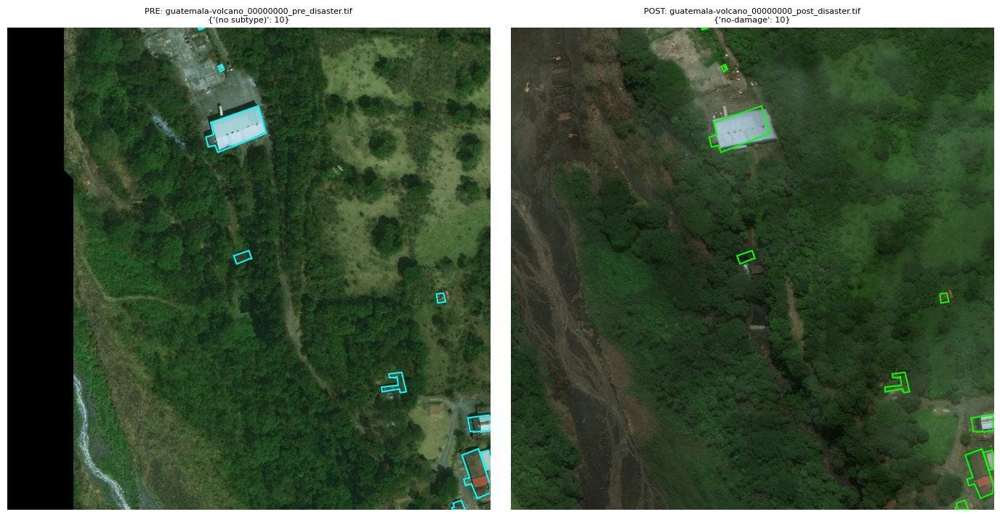

In [7]:
COLORS = {
    "no-damage": "lime",
    "minor-damage": "yellow",
    "major-damage": "orange",
    "destroyed": "red",
    "un-classified": "gray",
}


def parse_wkt(wkt):
    """Turn 'POLYGON ((x y, x y, ...))' into an (N, 2) array (outer ring only)."""
    if not wkt.startswith("POLYGON"):
        return None
    inner = wkt[wkt.index("((") + 2 : wkt.rindex("))")]
    ring = inner.split("),")[0]
    return np.array([[float(v) for v in p.split()] for p in ring.split(",")])


def draw_buildings(ax, lab):
    found = Counter()
    for b in lab["features"]["xy"]:
        pts = parse_wkt(b["wkt"])
        if pts is None:
            continue
        sub = b["properties"].get("subtype", "(no subtype)")
        found[sub] += 1
        ax.add_patch(Polygon(pts, closed=True, fill=False,
                             edgecolor=COLORS.get(sub, "cyan"), linewidth=1.5))
    return found


def show_with_labels(pre, post):
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    for ax, path, title in zip(axes, (pre, post), ("PRE", "POST")):
        ax.imshow(load_rgb(path))
        found = draw_buildings(ax, load_label(path))
        ax.set_title(f"{title}: {path.name}\n{dict(found)}", fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


# Change the index to look at another pair
show_with_labels(*pairs[0])

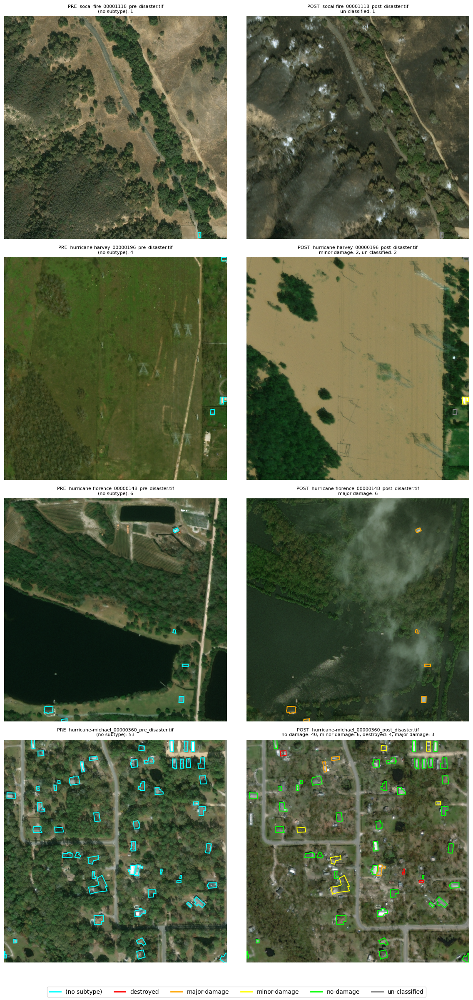

In [9]:
from matplotlib.lines import Line2D


def show_pairs_with_labels(pairs, n=4, seed=42):
    """Show n random pre/post pairs with building outlines.
    Outline color = damage label. Title = number of buildings per label."""
    random.seed(seed)
    sample = random.sample(pairs, min(n, len(pairs)))

    fig, axes = plt.subplots(len(sample), 2, figsize=(12, 6 * len(sample)))
    axes = np.atleast_2d(axes)
    all_labels = set()

    for row, (pre, post) in zip(axes, sample):
        for ax, path, name in zip(row, (pre, post), ("PRE", "POST")):
            ax.imshow(load_rgb(path))
            found = draw_buildings(ax, load_label(path))   # draws the outlines
            all_labels.update(found)
            text = ", ".join(f"{k}: {v}" for k, v in found.items()) or "no buildings"
            ax.set_title(f"{name}  {path.name}\n{text}", fontsize=8)
            ax.axis("off")

    handles = [Line2D([0], [0], color=COLORS.get(s, "cyan"), lw=2, label=s)
               for s in sorted(all_labels)]
    fig.legend(handles=handles, loc="lower center", ncol=max(1, len(handles)))
    plt.tight_layout(rect=[0, 0.03, 1, 1])
    plt.show()


show_pairs_with_labels(pairs, n=4)

## 7. Count damage labels in the whole split
This reads every post-disaster label file in the folder, so it can take a little time.

In [8]:
counts = Counter()
per_disaster = {}

for pre, post in pairs:
    disaster = post.name.split("_")[0]
    for b in load_label(post)["features"]["xy"]:
        sub = b["properties"].get("subtype", "(no subtype)")
        counts[sub] += 1
        per_disaster.setdefault(disaster, Counter())[sub] += 1

print("All buildings in this split:", sum(counts.values()))
print(dict(counts))
print()
for d, c in sorted(per_disaster.items()):
    print(d, dict(c))

All buildings in this split: 162787
{'no-damage': 117426, 'minor-damage': 14980, 'destroyed': 13227, 'major-damage': 14161, 'un-classified': 2993}

guatemala-volcano {'no-damage': 639, 'minor-damage': 9, 'destroyed': 25, 'major-damage': 9, 'un-classified': 174}
hurricane-florence {'no-damage': 4689, 'minor-damage': 132, 'un-classified': 326, 'major-damage': 1245, 'destroyed': 54}
hurricane-harvey {'major-damage': 8238, 'minor-damage': 2663, 'no-damage': 11423, 'un-classified': 289, 'destroyed': 401}
hurricane-matthew {'minor-damage': 6548, 'no-damage': 2515, 'major-damage': 1945, 'destroyed': 2147, 'un-classified': 784}
hurricane-michael {'no-damage': 14588, 'minor-damage': 5207, 'un-classified': 232, 'major-damage': 1902, 'destroyed': 757}
mexico-earthquake {'no-damage': 32066, 'minor-damage': 110, 'un-classified': 75, 'major-damage': 18, 'destroyed': 2}
midwest-flooding {'no-damage': 8128, 'un-classified': 285, 'destroyed': 75, 'major-damage': 119, 'minor-damage': 149}
palu-tsunami {